In [1]:
from deepagents import  create_deep_agent
from langchain_quickjs import CodeInterpreterMiddleware
from dotenv import  load_dotenv
import os 
from langchain_groq import  ChatGroq 
from urllib.request import  urlopen
from langgraph.checkpoint.memory import  MemorySaver
from deepagents.backends.utils import  create_file_data
from deepagents.backends import  StateBackend 

from pathlib import  Path

In [2]:
from pathlib import Path
from deepagents.backends.utils import create_file_data

def load_skill_files(skills_root: str = "skills", skill_name: str | None = None) -> dict:
    """
    Recursively scans the skills directory on disk and returns a dictionary
    formatted for deepagents' StateBackend virtual filesystem.
    """
    root = Path(skills_root)
    target = root / skill_name if skill_name else root
    
    if not target.exists():
        raise FileNotFoundError(f"Directory not found: {target.resolve()}")

    skill_files = {}
    for file_path in target.rglob("*"):
        if file_path.is_file():
            # Generates virtual path like: '/skills/langgraph/skill.md'
            virtual_path = f"/{file_path.as_posix()}"
            skill_files[virtual_path] = create_file_data(file_path.read_text(encoding="utf-8"))
            
    return skill_files

# Option A: Load only the 'langgraph' skill
skillfiles = load_skill_files("skills", skill_name="langgraph")

# Option B: Load all skills under the 'skills' folder
# skillfiles = load_skill_files("skills")

print("Files prepared for agent:", list(skillfiles.keys()))



Files prepared for agent: ['/skills/langgraph/instructions.md', '/skills/langgraph/skill.md', '/skills/langgraph/examples/agent_workflow.md']


In [3]:


skills_root = Path("skills")

# Automatically finds all subdirectories under 'skills/' that contain 'skill.md'
skilles_file = {
    f"/skills/{d.name}/skill.md": create_file_data((d / "skill.md").read_text(encoding="utf-8"))
    for d in skills_root.iterdir()
    if d.is_dir() and (d / "skill.md").exists()
}

print(f"Discovered skills: {list(skilles_file.keys())}")


Discovered skills: ['/skills/aws/skill.md', '/skills/langgraph/skill.md', '/skills/python/skill.md']


In [4]:
skilles_file

{'/skills/aws/skill.md': {'content': '# AWS Skill\n\n## Overview\nSkill module for interacting with and managing Amazon Web Services (AWS) infrastructure and cloud resources.\n\n## Scope & Capabilities\n- **Compute**: EC2 instance provisioning, status monitoring, and lifecycle management.\n- **Storage**: S3 bucket creation, object lifecycle, and access management.\n- **Security & IAM**: Least privilege access policies, credential management, and role-based access.\n- **Automation**: Infrastructure automation via `boto3` and AWS CLI.\n\n## Related Files\n- `instructions.md`: Guidelines and protocols for AWS resource operations.\n- `best_practices.md`: Security, cost optimization, and reliability standards.\n- `examples/ec2.md`: EC2 deployment and management examples.\n- `examples/s3.md`: S3 operations and bucket policy examples.\n',
  'encoding': 'utf-8',
  'created_at': '2026-10-22T14:59:02.039955+00:00',
  'modified_at': '2026-10-22T14:59:02.039955+00:00'},
 '/skills/langgraph/skill.m

In [5]:
load_dotenv()

os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_API_KEY"] = os.getenv("LANGSMITH_API_KEY")
os.environ["LANGCHAIN_PROJECT"] = os.getenv("LANGSMITH_PROJECT")

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")


llm = ChatGroq(model="openai/gpt-oss-120b")

In [6]:
#!pip install --upgrade langchain-core langsmith langchain langgraph deepagents langchain-quickjs

In [7]:
llm.invoke("hello")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hello". We should respond politely. There\'s no special instruction. So just greet.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.081405534, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.014099547, 'prompt_tokens_details': None, 'queue_time': 0.383417451, 'total_time': 0.095505081}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1641f-68ac-7c40-a037-3e0e3ec8c742-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasoning': 21}})

In [8]:
memor=MemorySaver()
backend=StateBackend

In [9]:
from langgraph.checkpoint.memory import MemorySaver
from deepagents.backends import StateBackend

# 1. Initialize conversation checkpointer
memory = MemorySaver()

# 2. Define backend (or use StateBackend by default)
backend = StateBackend()

# 3. Create the Deep Agent
agent = create_deep_agent(
    model=llm,
    backend=backend,
    skills=["/skills/"],
    checkpointer=memory
)


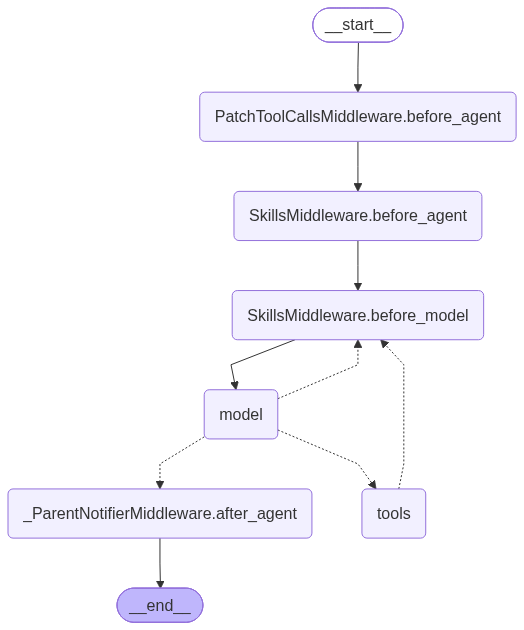

In [10]:
agent

In [11]:

config = {"configurable": {"thread_id": "session_1"}}

response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "List the skills available in /skills/ and summarize what the langgraph skill covers."
            }
        ],
        "files": skilles_file  # Provides your virtual skills to the agent
    },
    config=config
)

print(response["messages"][-1].content)


**Skills available in `/skills/`**

| Skill directory | Brief description (based on folder name) |
|-----------------|-------------------------------------------|
| `/skills/aws/` | Tools and guidance for working with Amazon Web Services (e.g., provisioning resources, using Boto3, deploying serverless apps). |
| `/skills/langgraph/` | Designing, building, and deploying stateful multi‑agent workflows with **LangGraph**. |
| `/skills/python/` | Python‑specific utilities, best‑practice patterns, and helper scripts for coding, testing, and automation. |

---

### Summary of the **LangGraph** skill (`/skills/langgraph/skill.md`)

The LangGraph skill provides a complete toolkit for creating **stateful, multi‑agent “cognitive graphs”** using the LangGraph library. Its main components are:

| Area | What the skill covers |
|------|-----------------------|
| **Graph Architecture** | How to define a `StateGraph` with a typed state schema (usually a `TypedDict`). |
| **Nodes & Edges** | Writing n

In [13]:

config = {"configurable": {"thread_id": "session_2"}}

response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "how do i setup EC2 instance in aws."
            }
        ],
        "files": skilles_file  # Provides your virtual skills to the agent
    },
    config=config
)

print(response["messages"][-1].content)

Below is a practical, step‑by‑step guide you can follow to launch and configure an Amazon EC2 instance.  
I’ve broken it into three main phases:

1. **Preparation (account & permissions)**  
2. **Launching the instance (console or CLI)**  
3. **Connecting & basic post‑launch configuration**

You can use either the AWS Management Console (graphical UI) or the AWS CLI (command‑line). Choose the one you’re most comfortable with; the steps are equivalent.

---

## 1️⃣ Preparation – Get ready in AWS

| Step | What to do | Why it matters |
|------|------------|----------------|
| **a. Sign‑in / create an AWS account** | Go to <https://aws.amazon.com/> → “Create an AWS Account”. | You need an account to access any AWS service. |
| **b. Set up a **root‑account** MFA** | In the **IAM** console → “Security credentials” → enable Multi‑Factor Authentication. | Protects the most privileged credentials. |
| **c. Create an IAM user for everyday work** | IAM → “Users” → “Add user”. Give a name (e.g., 